# Time Series Practice 2

**Dữ liệu:** Monthly Retail Sales (`a10.csv`), từ 1991-07 đến 2008-06.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
from practice_2.data.time_series_data import load_monthly_retail_sales, chronological_split
from practice_2.visualization.plots import save_series_plot

PROJECT_ROOT = next((p for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent] if (p / 'datasets' / 'raw' / 'a10.csv').is_file()), None)
if PROJECT_ROOT is None: raise FileNotFoundError('Không tìm thấy Practice 2 root')
RAW_PATH = PROJECT_ROOT / 'datasets' / 'raw' / 'a10.csv'
FIGURES_DIR = PROJECT_ROOT / 'outputs' / 'figures'
RESULTS_DIR = PROJECT_ROOT / 'outputs' / 'results'
FIGURES_DIR.mkdir(parents=True, exist_ok=True); RESULTS_DIR.mkdir(parents=True, exist_ok=True)


Matplotlib is building the font cache; this may take a moment.


# Exercise 1 — Khám phá dữ liệu (EDA)
<a id="exercise-1"></a>

### 1. Nạp dữ liệu

In [2]:
raw_frame = pd.read_csv(RAW_PATH)
raw_schema = pd.DataFrame({'column': raw_frame.columns, 'dtype': raw_frame.dtypes.astype(str).values})
print('shape:', raw_frame.shape)
raw_frame.info()
display(raw_frame.head())
display(raw_schema)
series = load_monthly_retail_sales(RAW_PATH)
train_series, test_series = chronological_split(series, train_fraction=0.80)
display(series.head().rename('value').to_frame())


shape: (204, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 204 entries, 0 to 203
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    204 non-null    object 
 1   value   204 non-null    float64
dtypes: float64(1), object(1)
memory usage: 3.3+ KB


,date,value
0,1991-07-01,3.526591
1,1991-08-01,3.180891
2,1991-09-01,3.252221
3,1991-10-01,3.611003
4,1991-11-01,3.565869


,column,dtype
0,date,object
1,value,float64


,value
date,
1991-07-01,3.526591
1991-08-01,3.180891
1991-09-01,3.252221
1991-10-01,3.611003
1991-11-01,3.565869


### 2. Kiểm tra data contract và time index

Kiểm tra schema, date range, monthly frequency, chronology, missing values, duplicate timestamps và missing intervals.

In [3]:
expected_index = pd.date_range(series.index.min(), series.index.max(), freq='MS')
validation = pd.DataFrame({'metric':['rows','start','end','index_type','frequency','missing_values','duplicate_timestamps','missing_intervals','chronological'],'value':[len(series),series.index.min(),series.index.max(),type(series.index).__name__,series.index.freqstr,int(series.isna().sum()),int(series.index.has_duplicates),len(expected_index.difference(series.index)),series.index.is_monotonic_increasing]})
boundary = pd.DataFrame({'split':['train','test'],'start':[train_series.index.min(),test_series.index.min()],'end':[train_series.index.max(),test_series.index.max()],'observations':[len(train_series),len(test_series)],'forecast_horizon':[None,len(test_series)]})
validation.to_csv(RESULTS_DIR / 'dataset_validation.csv', index=False); boundary.to_csv(RESULTS_DIR / 'train_test_boundary.csv', index=False)
display(validation); display(boundary)


,metric,value
0,rows,204
1,start,1991-07-01 00:00:00
2,end,2008-06-01 00:00:00
3,index_type,DatetimeIndex
4,frequency,MS
5,missing_values,0
6,duplicate_timestamps,0
7,missing_intervals,0
8,chronological,True


,split,start,end,observations,forecast_horizon
0,train,1991-07-01,2005-01-01,163,NaN
1,test,2005-02-01,2008-06-01,41,41.0


### 3. Thống kê mô tả

In [4]:
descriptive = series.describe().to_frame('value').T
rolling_std_first = float(series.iloc[:24].std())
rolling_std_last = float(series.iloc[-24:].std())
q1, q3 = series.quantile([0.25, 0.75])
iqr = q3 - q1
potential_outliers = series[(series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)]
display(descriptive)
display(pd.DataFrame({'metric':['first_24_std','last_24_std','q1','q3','iqr','potential_outlier_count'],'value':[rolling_std_first,rolling_std_last,q1,q3,iqr,len(potential_outliers)]}))


,count,mean,std,min,25%,50%,75%,max
value,204.0,10.69443,5.956998,2.81452,5.844095,9.319345,14.289964,29.665356


,metric,value
0,first_24_std,0.829561
1,last_24_std,3.511456
2,q1,5.844095
3,q3,14.289964
4,iqr,8.445869
5,potential_outlier_count,2.000000


### 4. Biểu đồ chuỗi thời gian

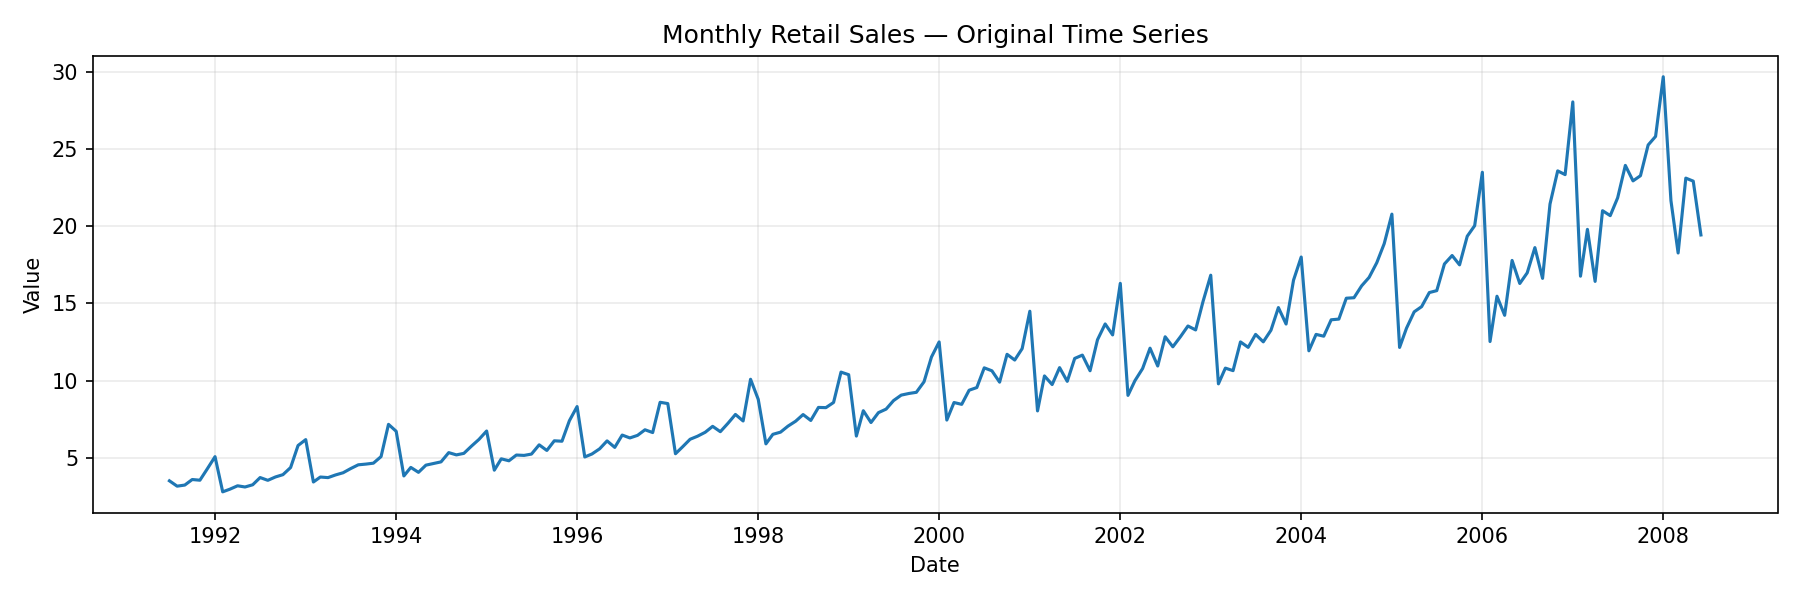

In [5]:
figure_path = FIGURES_DIR / '01_original_time_series.png'
save_series_plot(series, figure_path, 'Monthly Retail Sales — Original Time Series', 'Value')
display(Image(filename=str(figure_path)))


### 5. Kết luận E01

- **Xu hướng:** tăng rõ theo thời gian.
- **Mùa vụ:** có dấu hiệu lặp theo chu kỳ 12 tháng.
- **Tính dừng:** chuỗi có khả năng không dừng; kiểm định chính thức ở E02.

# Exercise 2 — Kiểm định ADF trên chuỗi gốc
<a id="exercise-2"></a>

### 1. Kiểm định ADF

**H₀:** chuỗi có unit root. Ngưỡng kiểm định: `α = 0.05`.

### 2. Kết quả trên chuỗi train gốc

Input: 163 quan sát train; 41 quan sát test không được sử dụng.

In [6]:
from practice_2.analysis.stationarity import run_adf
ADF_ALPHA = 0.05
adf_original, critical_original = run_adf(train_series, alpha=ADF_ALPHA)
adf_original.to_csv(RESULTS_DIR / 'adf_original_series.csv', index=False)
critical_original.to_csv(RESULTS_DIR / 'adf_original_critical_values.csv', index=False)
adf_statistic = float(adf_original.loc[adf_original['metric'].eq('adf_statistic'), 'value'].iloc[0])
p_value = float(adf_original.loc[adf_original['metric'].eq('p_value'), 'value'].iloc[0])
critical_comparison = critical_original.copy()
critical_comparison['statistic_below_critical'] = adf_statistic < critical_comparison['value']
display(adf_original)
display(critical_original)
display(critical_comparison)


,metric,value
0,adf_statistic,2.230893
1,p_value,0.998907
2,used_lag,14
3,n_observations,148
4,alpha,0.05
5,decision,fail to reject H0


,critical_value,value
0,1%,-3.475325
1,5%,-2.881275
2,10%,-2.577293


,critical_value,value,statistic_below_critical
0,1%,-3.475325,False
1,5%,-2.881275,False
2,10%,-2.577293,False


### 3. Kết luận E02

ADF statistic = **2.230893**, p-value = **0.998907 > 0.05** → fail to reject H₀. Chuỗi train gốc **chưa dừng**.

# Exercise 3 — Sai phân và kiểm định lại
<a id="exercise-3"></a>

### 1. First difference trên chuỗi train

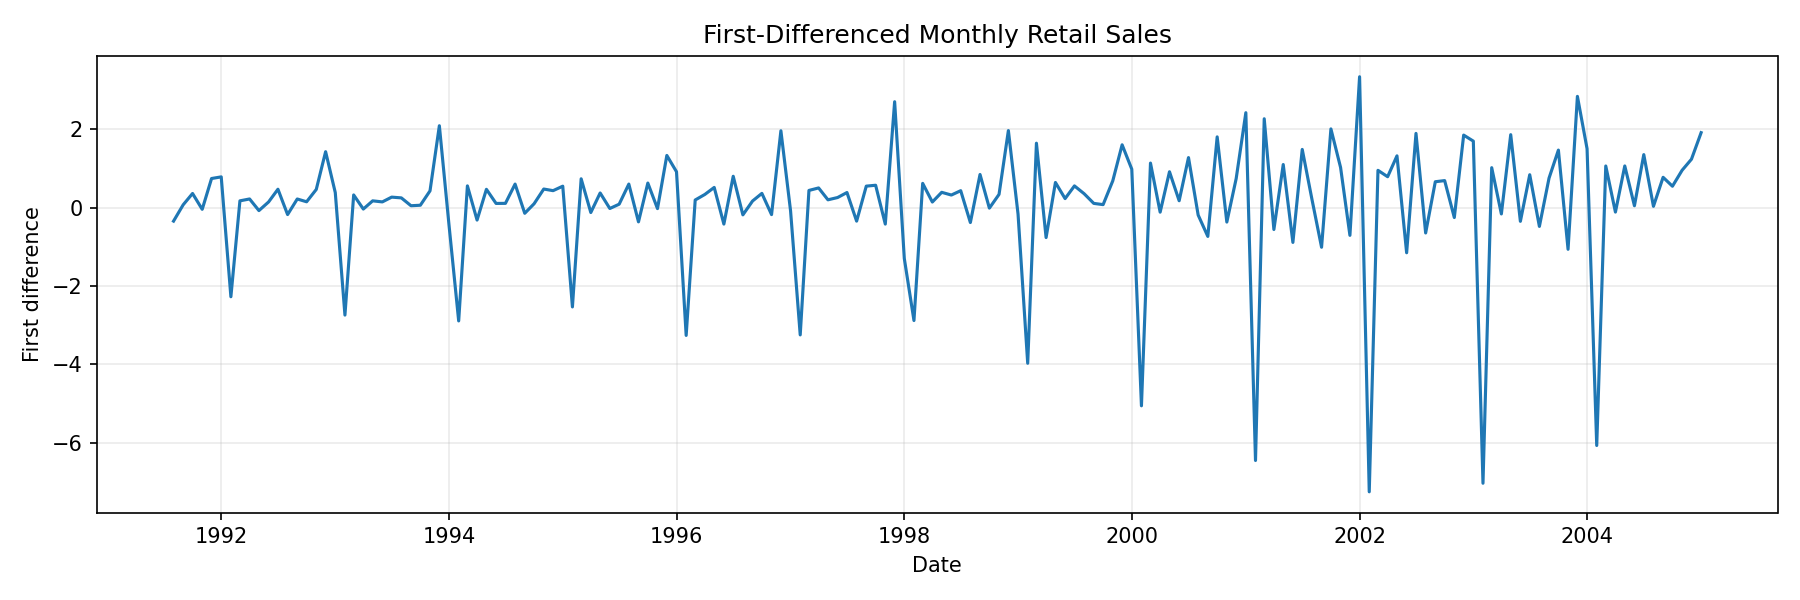

original training observations: 163
differenced observations: 162


In [7]:
from practice_2.analysis.stationarity import first_difference, log_first_difference
differenced = first_difference(train_series)
differenced_figure = FIGURES_DIR / '02_first_differenced_series.png'
save_series_plot(differenced, differenced_figure, 'First-Differenced Monthly Retail Sales', 'First difference')
display(Image(filename=str(differenced_figure)))
print('original training observations:', len(train_series))
print('differenced observations:', len(differenced))


### 2. ADF sau first difference

In [8]:
adf_diff, critical_diff = run_adf(differenced, alpha=ADF_ALPHA)
diff_statistic = float(adf_diff.loc[adf_diff['metric'].eq('adf_statistic'), 'value'].iloc[0])
diff_p_value = float(adf_diff.loc[adf_diff['metric'].eq('p_value'), 'value'].iloc[0])
raw_selected_d = 1 if diff_p_value <= ADF_ALPHA else 'REVIEW_REQUIRED'
diff_comparison = critical_diff.copy()
diff_comparison['statistic_below_critical'] = diff_statistic < diff_comparison['value']
raw_difference_decision = pd.concat([adf_diff, pd.DataFrame({'metric':['selected_d'], 'value':[raw_selected_d]})], ignore_index=True)
adf_diff.to_csv(RESULTS_DIR / 'adf_differenced_series.csv', index=False)
critical_diff.to_csv(RESULTS_DIR / 'adf_differenced_critical_values.csv', index=False)
display(raw_difference_decision)
display(diff_comparison)


,metric,value
0,adf_statistic,-1.706074
1,p_value,0.427986
2,used_lag,13
3,n_observations,148
4,alpha,0.05
5,decision,fail to reject H0
6,selected_d,REVIEW_REQUIRED


,critical_value,value,statistic_below_critical
0,1%,-3.475325,False
1,5%,-2.881275,False
2,10%,-2.577293,False


### 3. Kết quả first difference

ADF statistic = **-1.706074**, p-value = **0.427986 > 0.05** → chuỗi vẫn chưa dừng.

### 4. Log transformation + first difference

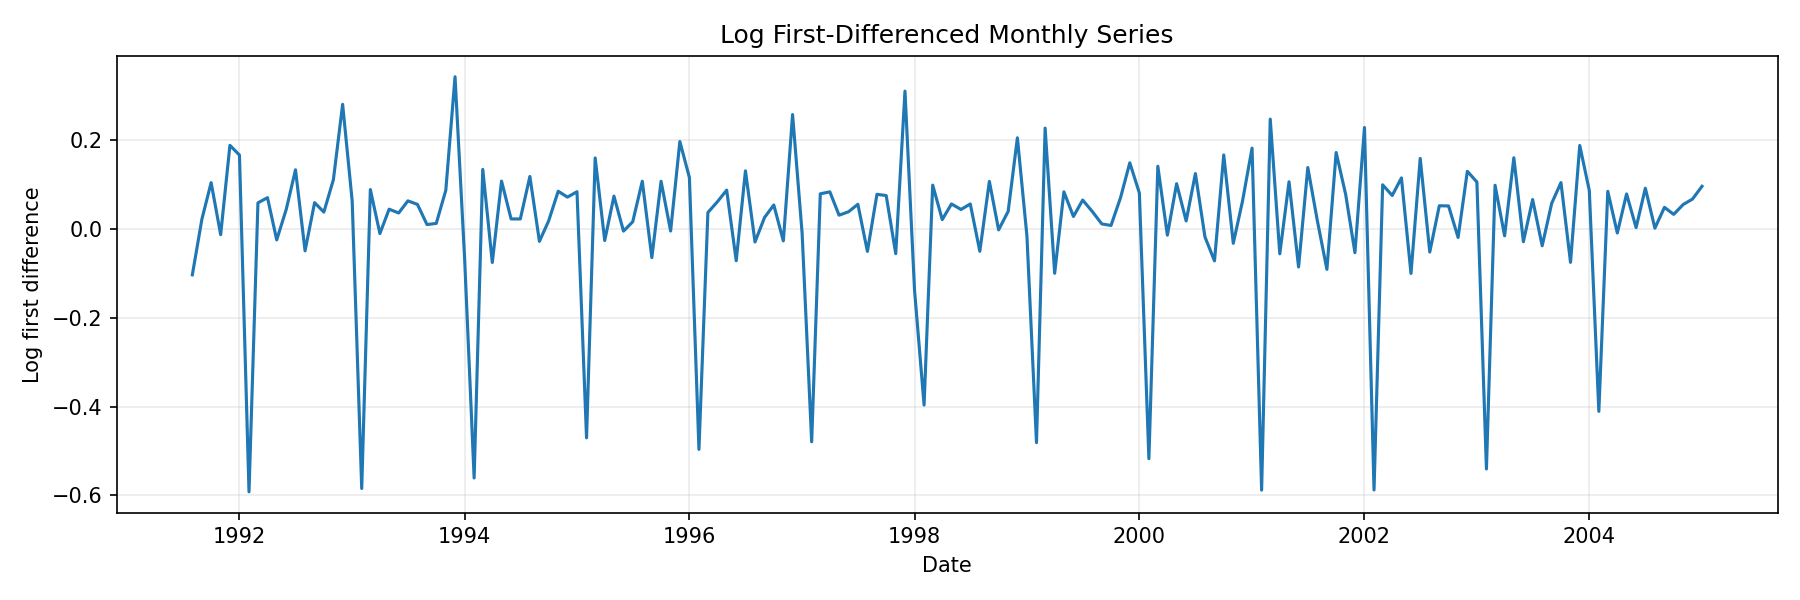

all training values positive: True
original training observations: 163
log first-differenced observations: 162
remaining missing values: 0


In [9]:
all_train_values_positive = bool((train_series > 0).all())
log_differenced = log_first_difference(train_series)
log_differenced_figure = FIGURES_DIR / '02_log_first_differenced_series.png'
save_series_plot(log_differenced, log_differenced_figure, 'Log First-Differenced Monthly Series', 'Log first difference')
display(Image(filename=str(log_differenced_figure)))
print('all training values positive:', all_train_values_positive)
print('original training observations:', len(train_series))
print('log first-differenced observations:', len(log_differenced))
print('remaining missing values:', int(log_differenced.isna().sum()))


In [10]:
adf_log_diff, critical_log_diff = run_adf(log_differenced, alpha=ADF_ALPHA)
log_diff_statistic = float(adf_log_diff.loc[adf_log_diff['metric'].eq('adf_statistic'), 'value'].iloc[0])
log_diff_p_value = float(adf_log_diff.loc[adf_log_diff['metric'].eq('p_value'), 'value'].iloc[0])
log_diff_decision = str(adf_log_diff.loc[adf_log_diff['metric'].eq('decision'), 'value'].iloc[0])
stationarity_supported = log_diff_p_value <= ADF_ALPHA
selected_d = 1 if stationarity_supported else 'REVIEW_REQUIRED'
selected_transformation = 'natural_log' if stationarity_supported else 'REVIEW_REQUIRED'
handoff_state = 'READY_FOR_E04_REVIEW' if stationarity_supported else 'CLOSED'
log_diff_comparison = critical_log_diff.copy()
log_diff_comparison['statistic_below_critical'] = log_diff_statistic < log_diff_comparison['value']
transformation_comparison = pd.DataFrame({'transformation':['raw_first_difference','log_first_difference'],'adf_statistic':[diff_statistic,log_diff_statistic],'p_value':[diff_p_value,log_diff_p_value],'decision':['fail to reject H0' if diff_p_value > ADF_ALPHA else 'reject H0',log_diff_decision]})
differencing_decision = pd.DataFrame({'metric':['analysis_series','transformation','regular_differencing_order','adf_statistic','p_value','alpha','decision','stationarity_supported','e04_handoff'],'value':['log_first_differenced_training',selected_transformation,selected_d,log_diff_statistic,log_diff_p_value,ADF_ALPHA,log_diff_decision,stationarity_supported,handoff_state]})
adf_log_diff.to_csv(RESULTS_DIR / 'adf_log_first_differenced_series.csv', index=False)
critical_log_diff.to_csv(RESULTS_DIR / 'adf_log_first_differenced_critical_values.csv', index=False)
transformation_comparison.to_csv(RESULTS_DIR / 'e03_transformation_comparison.csv', index=False)
differencing_decision.to_csv(RESULTS_DIR / 'differencing_decision.csv', index=False)
display(adf_log_diff)
display(log_diff_comparison)
display(transformation_comparison)
display(differencing_decision)


,metric,value
0,adf_statistic,-3.659486
1,p_value,0.00472
2,used_lag,13
3,n_observations,148
4,alpha,0.05
5,decision,reject H0


,critical_value,value,statistic_below_critical
0,1%,-3.475325,True
1,5%,-2.881275,True
2,10%,-2.577293,True


,transformation,adf_statistic,p_value,decision
0,raw_first_difference,-1.706074,0.427986,fail to reject H0
1,log_first_difference,-3.659486,0.004720,reject H0


,metric,value
0,analysis_series,log_first_differenced_training
1,transformation,natural_log
2,regular_differencing_order,1
3,adf_statistic,-3.659486
4,p_value,0.00472
5,alpha,0.05
6,decision,reject H0
7,stationarity_supported,True
8,e04_handoff,READY_FOR_E04_REVIEW


### 5. Kết luận E03

ADF statistic = **-3.659486**, p-value = **0.004720 < 0.05** → chuỗi `log + first difference` đã dừng. Chọn **`natural_log`** và **`d = 1`**.